In [1]:
print("hi")

hi


## Task 1: Multi-Class Benchmark Classification Pipeline (Wine Dataset)

---

### 📌 Project Overview & Requirements
Implement an end-to-end supervised classification workflow on a benchmark dataset.
- Load dataset using **Pandas**
- Perform exploratory pairplots with **Seaborn**
- Standardize continuous features with **StandardScaler**
- Split dataset (80/20 train/test split)
- Train **Logistic Regression** and **Decision Tree Classifier**
- Benchmark **Accuracy, Precision, Recall, and F1-Score**
- Plot confusion matrix heatmaps and decision boundary visualizations

## Step 1: Downloading required libraries

In [ ]:
!pip install scikit-learn pandas matplotlib seaborn

  Using cached scikit_learn-1.9.1-cp313-cp313-win_amd64.whl.metadata (9.3 kB)
  Using cached matplotlib-3.11.2-cp313-cp313-win_amd64.whl.metadata (80 kB)
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached scipy-1.18.1-cp313-cp313-win_amd64.whl.metadata (61 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached contourpy-1.4.0-cp313-cp313-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.67.0-cp313-cp313-win_amd64.whl.metadata (139 kB)
  Using cached kiwisolver-1.5.1-cp313-cp313-win_amd64.whl.metadata (5.2 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached scikit_learn-1.9.1-cp313-cp313-win_amd64.whl (8.2 MB)
Using cached matplotlib-3.11.2-cp313-cp313-win_amd64.whl (9.3 MB)
Using cached seaborn


[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## Step 2: Importing all libraries

In [5]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_wine
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from matplotlib.colors import ListedColormap

# Set plot aesthetic style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 100

## Step 3: Load and Inspect Benchmark Dataset
Load the Wine classification dataset via Pandas and inspect target classes and feature shapes.

In [6]:
data = load_wine()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="target")

print(f"Dataset Shape: {X.shape}")
print(f"Target Classes: {list(data.target_names)}")
X.head()

Dataset Shape: (178, 13)
Target Classes: [np.str_('class_0'), np.str_('class_1'), np.str_('class_2')]


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


## Step 4: Exploratory Data Analysis (Seaborn Pairplot)
Perform feature relationship exploration using Seaborn pairplots.

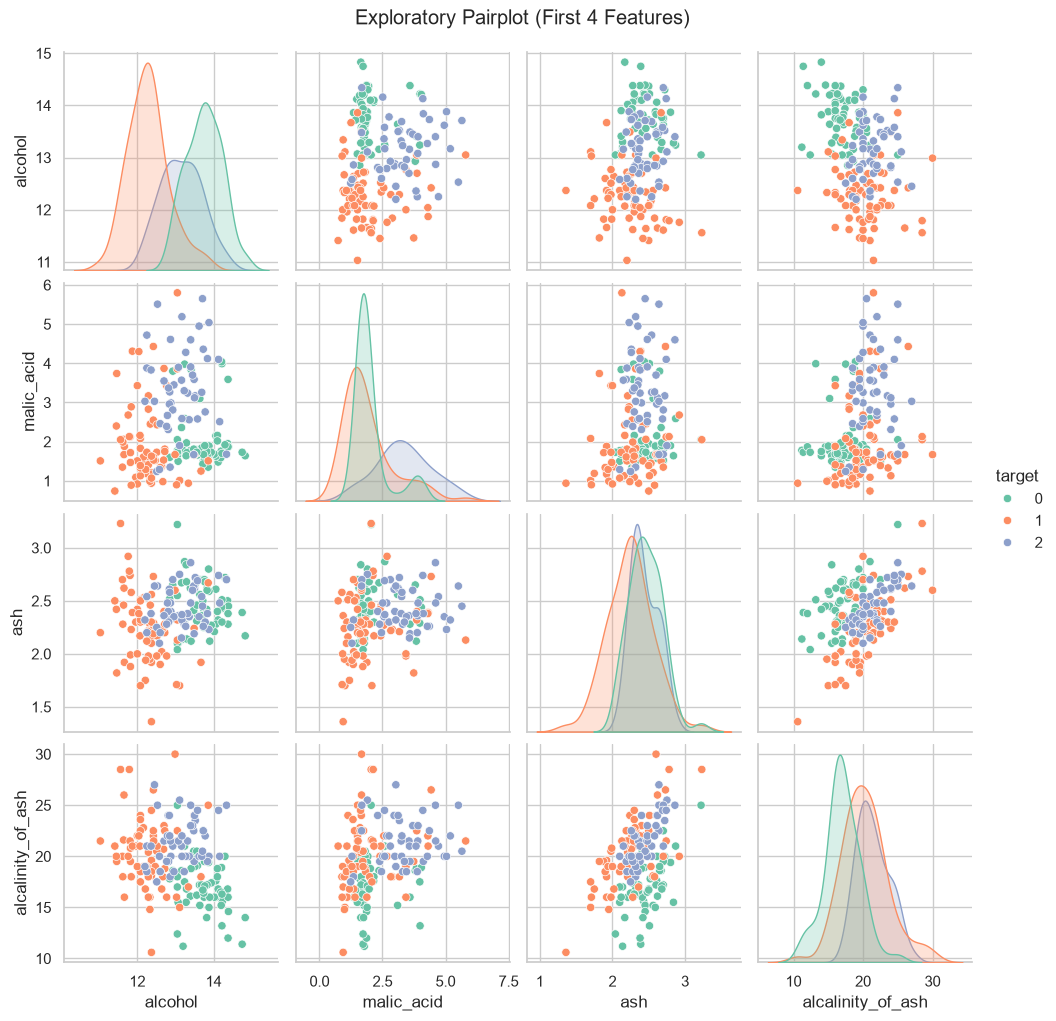

In [7]:
df_plot = X.copy()
df_plot['target'] = y

pairplot_fig = sns.pairplot(df_plot, vars=data.feature_names[:4], hue='target', palette='Set2')
plt.suptitle("Exploratory Pairplot (First 4 Features)", y=1.02)
plt.savefig("exploratory_pairplot.png")
plt.show()

## Step 5: Train-Test Split (80/20) & Feature Normalization
Split data into 80% training and 20% testing sets, then apply `StandardScaler`.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training set size: {X_train_scaled.shape}")
print(f"Testing set size: {X_test_scaled.shape}")

Training set size: (142, 13)
Testing set size: (36, 13)


## Step 6: Model Training & Performance Benchmarking
Train Logistic Regression and Decision Tree models and benchmark accuracy, precision, recall, and F1-score.

In [9]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree Classifier": DecisionTreeClassifier(random_state=42)
}

results = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average='weighted')
    rec = recall_score(y_test, y_pred, average='weighted')
    f1 = f1_score(y_test, y_pred, average='weighted')

    results[name] = {
        "model": model,
        "y_pred": y_pred,
        "metrics": {"Accuracy": acc, "Precision": prec, "Recall": rec, "F1-Score": f1}
    }

    print(f"=== {name} Performance ===")
    print(f"Accuracy:  {acc:.4f} | Precision: {prec:.4f} | Recall: {rec:.4f} | F1-Score: {f1:.4f}\n")
    print("Classification Report:")
    print(classification_report(y_test, y_pred, target_names=data.target_names))
    print("-" * 60)

=== Logistic Regression Performance ===
Accuracy:  0.9722 | Precision: 0.9741 | Recall: 0.9722 | F1-Score: 0.9720

Classification Report:
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       0.93      1.00      0.97        14
     class_2       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36

------------------------------------------------------------
=== Decision Tree Classifier Performance ===
Accuracy:  0.9444 | Precision: 0.9514 | Recall: 0.9444 | F1-Score: 0.9450

Classification Report:
              precision    recall  f1-score   support

     class_0       1.00      0.92      0.96        12
     class_1       0.88      1.00      0.93        14
     class_2       1.00      0.90      0.95        10

    accuracy                           0.94        36
   ma

## Step 7: Confusion Matrix Heatmaps
Plot side-by-side confusion matrix heatmaps to visualize prediction accuracy across classes.

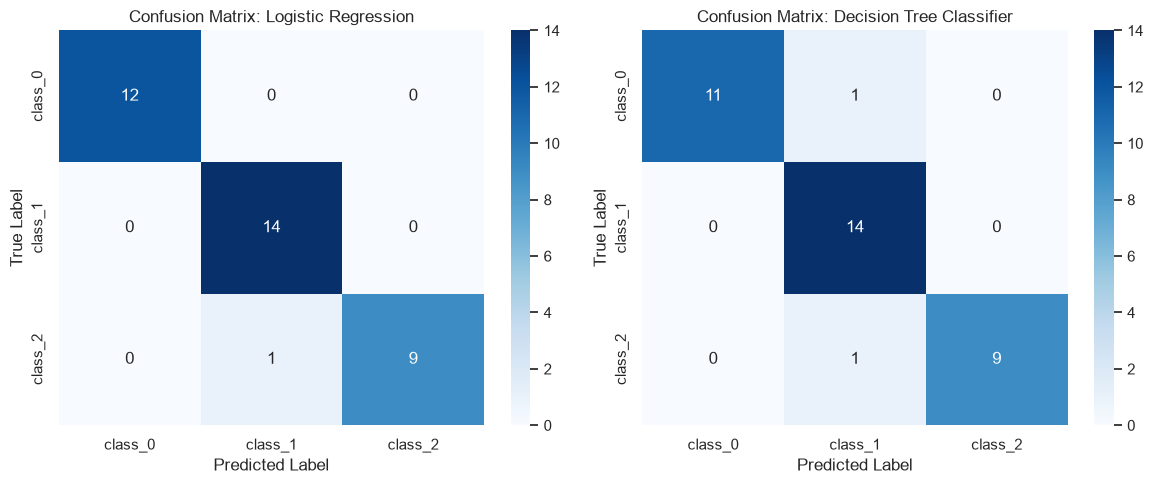

In [10]:
plt.figure(figsize=(12, 5))
for idx, (name, res) in enumerate(results.items(), 1):
    plt.subplot(1, 2, idx)
    cm = confusion_matrix(y_test, res["y_pred"])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", 
                xticklabels=data.target_names, yticklabels=data.target_names)
    plt.title(f"Confusion Matrix: {name}")
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")

plt.tight_layout()
plt.savefig("confusion_matrices.png")
plt.show()

## Step 8: Decision Boundary Visualizations
Plot 2D decision boundary spaces for both classifiers using the first two principal feature components.

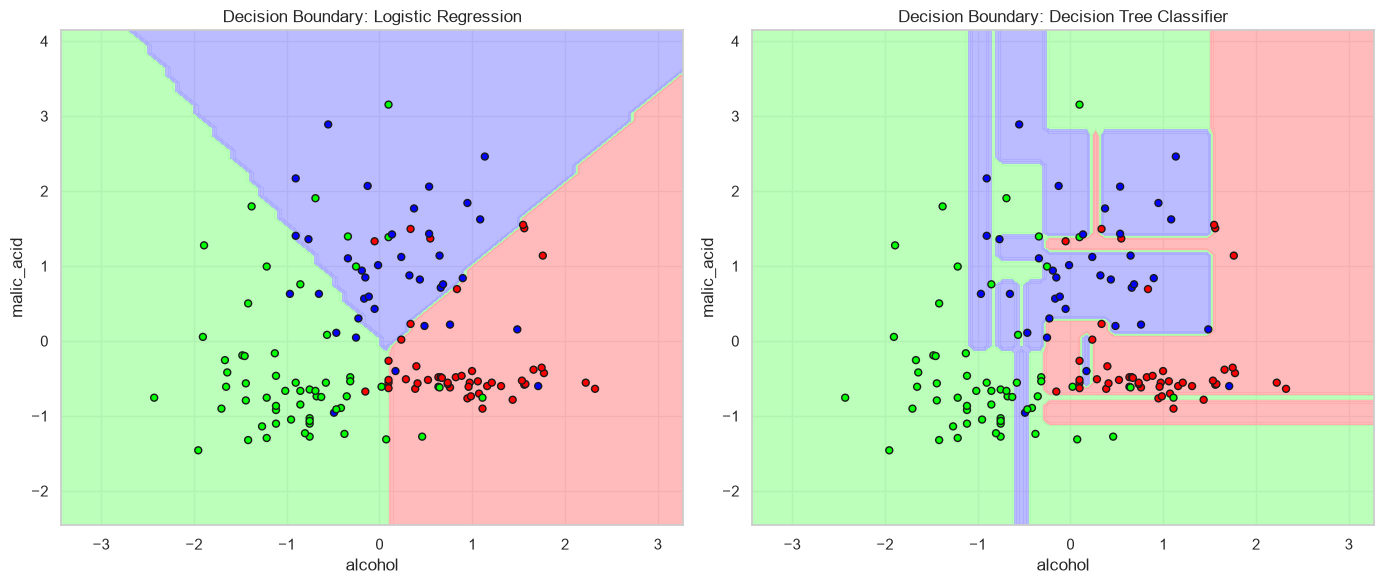

In [11]:
X_2d = X_train_scaled[:, :2]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
cmap_light = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF'])
cmap_bold = ['#FF0000', '#00FF00', '#0000FF']

x_min, x_max = X_2d[:, 0].min() - 1, X_2d[:, 0].max() + 1
y_min, y_max = X_2d[:, 1].min() - 1, X_2d[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1),
                     np.arange(y_min, y_max, 0.1))

for idx, (name, _) in enumerate(models.items()):
    clf_2d = LogisticRegression(max_iter=1000, random_state=42) if "Logistic" in name else DecisionTreeClassifier(random_state=42)
    clf_2d.fit(X_2d, y_train)

    Z = clf_2d.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    ax = axes[idx]
    ax.contourf(xx, yy, Z, cmap=cmap_light, alpha=0.8)
    scatter = ax.scatter(X_2d[:, 0], X_2d[:, 1], c=y_train, cmap=ListedColormap(cmap_bold), edgecolor='k', s=25)
    ax.set_title(f"Decision Boundary: {name}")
    ax.set_xlabel(data.feature_names[0])
    ax.set_ylabel(data.feature_names[1])

plt.tight_layout()
plt.savefig("decision_boundaries.png")
plt.show()